
# ⚽ WHY NOT KOREA?
## 대한민국은 왜 월드컵에서 우승하지 못할까?

**MBC AI 데이터 저널리즘 실습**

- 날짜: 2026년 10월 29일
- 데이터 출처: Kaggle FIFA World Cup Dataset
- 분석 기간: 2002~2022년
- 개발 환경: Google Colab
- 분석 언어: Python
- 라이브러리: Pandas, Matplotlib
- AI 기사 생성: OpenAI API

### 프로젝트 목표
대한민국의 월드컵 성적을 분석하고,
우승 경험국 및 상위권 진출팀의 기록과 비교한다.

Python으로 통계를 계산하고 시각화한 뒤,
Fact Sheet를 기반으로 AI 기사를 생성한다.

### 분석 과정
1. 데이터 수집 및 전처리
2. 대한민국 역대 성적 분석
3. 국가별 득점·실점·승률 비교
4. 월드컵 최종 성적별 통계 분석
5. 상관관계 분석
6. OpenAI API를 이용한 기사 작성
7. AI 팩트체크 및 교열
8. Python 수치 검증

### 주요 결과
- 대한민국의 2002~2022년 승률: 29.17%
- 경기당 득점: 1.17골
- 경기당 실점: 1.46골
- 득점과 최종 순위의 상관계수: -0.678
- 실점과 최종 순위의 상관계수: +0.637

### 검증 상태
Python 내부 통계 검증: 9/9 PASS

FIFA 공식 원자료 대조: 미완료

### 결론
대한민국은 비교 국가보다 경기당 득점이 적고
실점이 많은 경향을 보였다.

다만 이 결과만으로 월드컵 우승 실패의
근본적인 원인을 단정할 수는 없다.


In [1]:

from google.colab import files

uploaded = files.upload()



Saving archive.zip to archive (1).zip


In [3]:

import zipfile
import os

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/worldcup")

print(os.listdir("/content/worldcup"))


['FIFA - 1998.csv', 'FIFA - 1970.csv', 'FIFA - 1938.csv', 'FIFA - 2006.csv', 'FIFA - 1954.csv', 'FIFA - 1986.csv', 'FIFA - 1934.csv', 'FIFA - 1950.csv', 'FIFA - 1982.csv', 'FIFA - 1930.csv', 'FIFA - 2014.csv', 'FIFA - 1958.csv', 'FIFA - 1994.csv', 'FIFA - 1990.csv', 'FIFA - 1962.csv', 'FIFA - 2010.csv', 'FIFA - 1974.csv', 'FIFA - 1966.csv', 'FIFA - 1978.csv', 'FIFA - 2022.csv', 'FIFA - World Cup Summary.csv', 'FIFA - 2002.csv', 'FIFA - 2018.csv']


In [4]:

import pandas as pd
import os

folder = "/content/worldcup"

# CSV 파일 목록 확인
csv_files = sorted([
    f for f in os.listdir(folder)
    if f.endswith(".csv")
])

print("CSV 파일 개수:", len(csv_files))
print("\n파일 목록:")
print(csv_files)

# 2022년 월드컵 데이터 확인
file_2022 = [f for f in csv_files if "2022" in f]

if file_2022:
    df = pd.read_csv(os.path.join(folder, file_2022[0]))

    print("\n2022 월드컵 데이터:")
    display(df.head())

    print("\n컬럼 이름:")
    print(df.columns.tolist())
else:
    print("2022년 CSV 파일이 없습니다.")


CSV 파일 개수: 23

파일 목록:
['FIFA - 1930.csv', 'FIFA - 1934.csv', 'FIFA - 1938.csv', 'FIFA - 1950.csv', 'FIFA - 1954.csv', 'FIFA - 1958.csv', 'FIFA - 1962.csv', 'FIFA - 1966.csv', 'FIFA - 1970.csv', 'FIFA - 1974.csv', 'FIFA - 1978.csv', 'FIFA - 1982.csv', 'FIFA - 1986.csv', 'FIFA - 1990.csv', 'FIFA - 1994.csv', 'FIFA - 1998.csv', 'FIFA - 2002.csv', 'FIFA - 2006.csv', 'FIFA - 2010.csv', 'FIFA - 2014.csv', 'FIFA - 2018.csv', 'FIFA - 2022.csv', 'FIFA - World Cup Summary.csv']

2022 월드컵 데이터:


,Position,Team,Games Played,Win,Draw,Loss,Goals For,Goals Against,Goal Difference,Points
0,1,Argentina,7,6,0,1,15,8,7,18
1,2,France,7,5,0,2,16,8,8,15
2,3,Croatia,7,4,2,1,8,7,1,14
3,4,Morocco,7,4,1,2,6,5,1,13
4,5,England,5,3,1,1,13,4,9,10



컬럼 이름:
['Position', 'Team', 'Games Played', 'Win', 'Draw', 'Loss', 'Goals For', 'Goals Against', 'Goal Difference', 'Points']


In [5]:

# 대한민국 데이터 찾기
korea = df[
    df["Team"].str.contains(
        "Korea", case=False, na=False
    )
]

print("대한민국 2022 월드컵 성적")
display(korea)


대한민국 2022 월드컵 성적


,Position,Team,Games Played,Win,Draw,Loss,Goals For,Goals Against,Goal Difference,Points
15,16,South Korea,4,1,1,2,5,8,-3,4


In [7]:

import pandas as pd
import os
import re

korea_records = []

for filename in csv_files:

    # 파일 이름에서 연도 검색
    match = re.search(r"\d{4}", filename)

    # 연도가 없는 파일은 건너뛰기
    if match is None:
        print("건너뛴 파일:", filename)
        continue

    year = int(match.group())

    # CSV 파일 읽기
    temp_df = pd.read_csv(
        os.path.join(folder, filename)
    )

    # 대한민국 데이터만 선택
    korea_df = temp_df[
        temp_df["Team"].astype(str).str.fullmatch(
            r"South Korea|Korea Republic",
            case=False,
            na=False
        )
    ].copy()

    # 대한민국 기록이 있다면 저장
    if not korea_df.empty:
        korea_df["Year"] = year
        korea_records.append(korea_df)

# 대한민국 역대 기록 합치기
if korea_records:

    korea_history = pd.concat(
        korea_records,
        ignore_index=True
    )

    korea_history = korea_history.sort_values("Year")

    columns = [
        "Year", "Position", "Games Played",
        "Win", "Draw", "Loss",
        "Goals For", "Goals Against"
    ]

    display(korea_history[columns])

else:
    print("대한민국 데이터를 찾지 못했습니다.")



건너뛴 파일: FIFA - World Cup Summary.csv


,Year,Position,Games Played,Win,Draw,Loss,Goals For,Goals Against
0,1954,16,2,0,0,2,0,16
1,1986,20,3,0,1,2,4,7
2,1990,22,3,0,0,3,1,6
3,1994,20,3,0,2,1,4,5
4,1998,30,3,0,1,2,2,9
5,2002,4,7,3,2,2,8,6
6,2006,17,3,1,1,1,3,4
7,2010,15,4,1,1,2,6,8
8,2014,27,3,0,1,2,3,6
9,2018,25,3,1,0,2,3,3


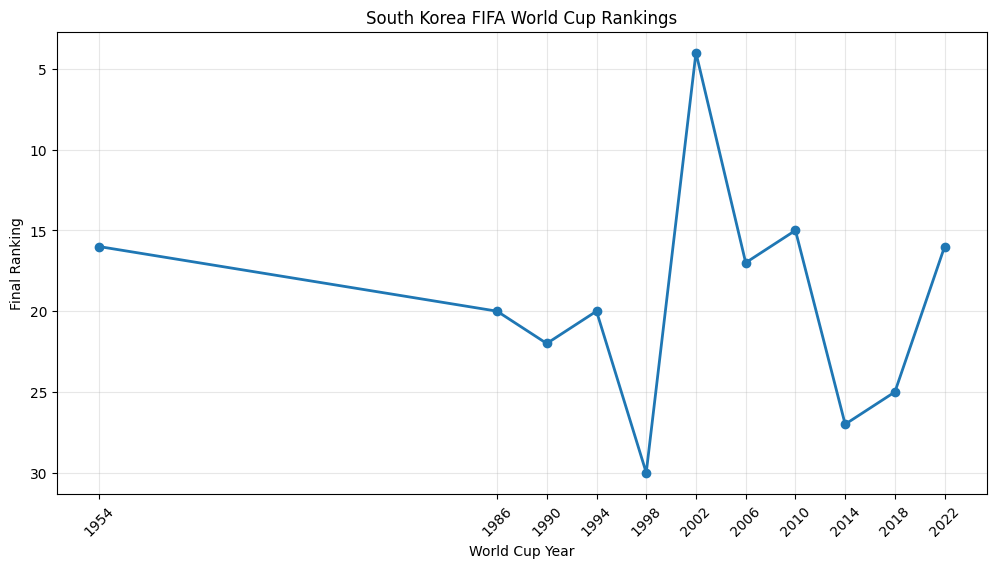

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    korea_history["Year"],
    korea_history["Position"],
    marker="o",
    linewidth=2
)

plt.gca().invert_yaxis()

plt.title("South Korea FIFA World Cup Rankings")
plt.xlabel("World Cup Year")
plt.ylabel("Final Ranking")

plt.xticks(korea_history["Year"], rotation=45)
plt.grid(True, alpha=0.3)

plt.show()


In [9]:

# 경기당 평균 득점
korea_history["Goals Per Game"] = (
    korea_history["Goals For"] /
    korea_history["Games Played"]
)

# 경기당 평균 실점
korea_history["Conceded Per Game"] = (
    korea_history["Goals Against"] /
    korea_history["Games Played"]
)

# 경기 승률
korea_history["Win Rate"] = (
    korea_history["Win"] /
    korea_history["Games Played"] * 100
)

# 분석 결과
display(
    korea_history[
        ["Year", "Goals Per Game",
         "Conceded Per Game", "Win Rate"]
    ].round(2)
)


,Year,Goals Per Game,Conceded Per Game,Win Rate
0,1954,0.00,8.00,0.00
1,1986,1.33,2.33,0.00
2,1990,0.33,2.00,0.00
3,1994,1.33,1.67,0.00
4,1998,0.67,3.00,0.00
5,2002,1.14,0.86,42.86
6,2006,1.00,1.33,33.33
7,2010,1.50,2.00,25.00
8,2014,1.00,2.00,0.00
9,2018,1.00,1.00,33.33


In [10]:

import pandas as pd
import os
import re

all_records = []

for filename in csv_files:

    match = re.search(r"\d{4}", filename)

    if match is None:
        continue

    year = int(match.group())

    if year < 2002 or year > 2022:
        continue

    temp = pd.read_csv(os.path.join(folder, filename))
    temp["Year"] = year

    all_records.append(temp)

# 모든 대회 데이터 합치기
worldcup = pd.concat(all_records, ignore_index=True)

# 국가 이름 통일
worldcup["Country"] = worldcup["Team"].replace({
    "South Korea": "South Korea",
    "Korea Republic": "South Korea",
    "Germany FR": "Germany"
})

# 비교 국가 선택
countries = [
    "South Korea",
    "Argentina",
    "Brazil",
    "Germany"
]

comparison = worldcup[
    worldcup["Country"].isin(countries)
].copy()

# 국가별 통계 합산
summary = comparison.groupby("Country").agg(
    Games=("Games Played", "sum"),
    Wins=("Win", "sum"),
    Goals=("Goals For", "sum"),
    Conceded=("Goals Against", "sum")
)

# 경기당 통계 계산
summary["Win Rate (%)"] = (
    summary["Wins"] / summary["Games"] * 100
)

summary["Goals Per Game"] = (
    summary["Goals"] / summary["Games"]
)

summary["Conceded Per Game"] = (
    summary["Conceded"] / summary["Games"]
)

display(summary.round(2))


,Games,Wins,Goals,Conceded,Win Rate (%),Goals Per Game,Conceded Per Game
Country,,,,,,,
Argentina,31,20,52,32,64.52,1.68,1.03
Brazil,34,23,64,30,67.65,1.88,0.88
Germany,34,23,70,27,67.65,2.06,0.79
South Korea,24,7,28,35,29.17,1.17,1.46


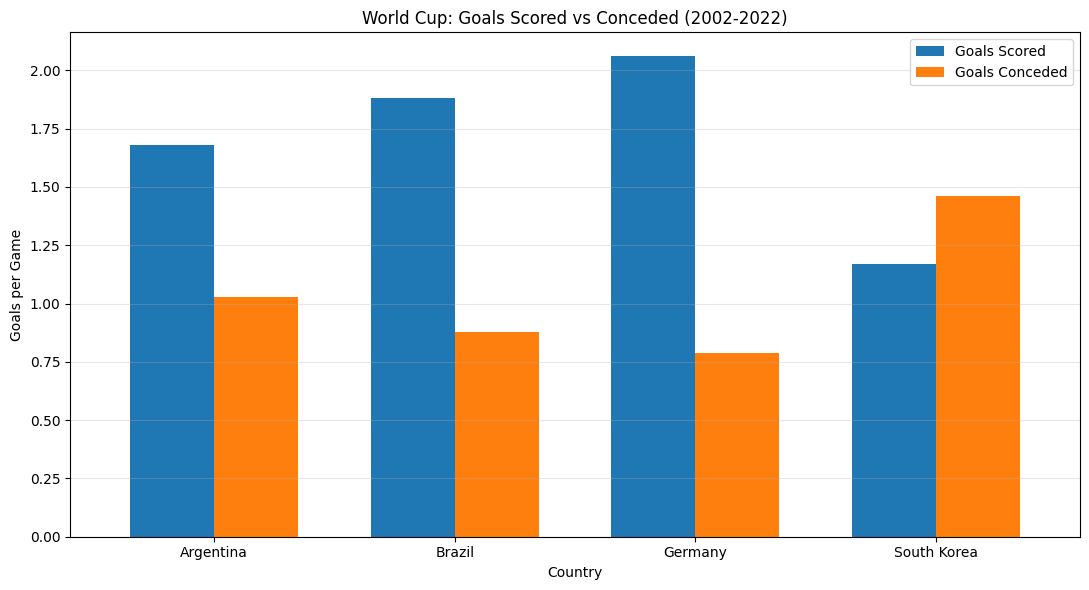

In [11]:

import matplotlib.pyplot as plt

# 국가별 득점과 실점 비교
chart_data = summary[
    ["Goals Per Game", "Conceded Per Game"]
].round(2)

ax = chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.7
)

plt.title("World Cup: Goals Scored vs Conceded (2002-2022)")
plt.xlabel("Country")
plt.ylabel("Goals per Game")
plt.xticks(rotation=0)
plt.legend(["Goals Scored", "Goals Conceded"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:

# 월드컵 우승국
champions = {
    2002: "Brazil",
    2006: "Italy",
    2010: "Spain",
    2014: "Germany",
    2018: "France",
    2022: "Argentina"
}

champion_records = []

for year, country in champions.items():

    result = worldcup[
        (worldcup["Year"] == year) &
        (worldcup["Country"] == country)
    ].copy()

    champion_records.append(result)

champion_df = pd.concat(
    champion_records, ignore_index=True
)

# 경기당 득점·실점
champion_df["Goals Per Game"] = (
    champion_df["Goals For"] /
    champion_df["Games Played"]
)

champion_df["Conceded Per Game"] = (
    champion_df["Goals Against"] /
    champion_df["Games Played"]
)

display(
    champion_df[
        ["Year", "Country", "Games Played",
         "Goals Per Game", "Conceded Per Game"]
    ].round(2)
)


,Year,Country,Games Played,Goals Per Game,Conceded Per Game
0,2002,Brazil,7,2.57,0.57
1,2006,Italy,7,1.71,0.29
2,2010,Spain,7,1.14,0.29
3,2014,Germany,7,2.57,0.57
4,2018,France,7,2.00,0.86
5,2022,Argentina,7,2.14,1.14


대한민국과 우승국 비교


,Team,Goals Scored,Goals Conceded
0,South Korea 2002,1.14,0.86
1,World Cup Champions Avg,2.02,0.62


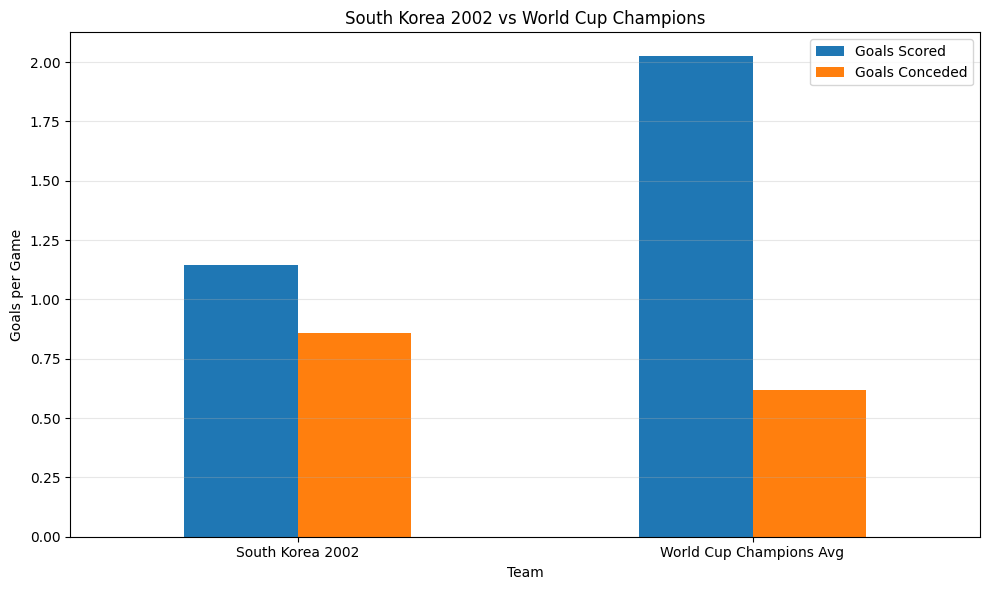

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# 2002년 대한민국 데이터
korea_2002 = korea_history[
    korea_history["Year"] == 2002
].iloc[0]

# 우승국 평균
champion_goals = champion_df["Goals Per Game"].mean()
champion_conceded = champion_df["Conceded Per Game"].mean()

# 비교 데이터 생성
compare_data = pd.DataFrame({
    "Team": ["South Korea 2002", "World Cup Champions Avg"],
    "Goals Scored": [
        korea_2002["Goals Per Game"],
        champion_goals
    ],
    "Goals Conceded": [
        korea_2002["Conceded Per Game"],
        champion_conceded
    ]
})

print("대한민국과 우승국 비교")
display(compare_data.round(2))

# 그래프
compare_data.set_index("Team").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("South Korea 2002 vs World Cup Champions")
plt.ylabel("Goals per Game")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:

import pandas as pd

# 기존 worldcup 데이터 복사
analysis = worldcup.copy()

# 경기당 득점과 실점 계산
analysis["Goals Per Game"] = (
    analysis["Goals For"] / analysis["Games Played"]
)

analysis["Conceded Per Game"] = (
    analysis["Goals Against"] / analysis["Games Played"]
)

# 최종 순위별 그룹 분류
def classify_team(position):
    if position <= 4:
        return "Top 4"
    elif position <= 8:
        return "Quarterfinal"
    elif position <= 16:
        return "Round of 16"
    else:
        return "Group Stage"

analysis["Stage"] = analysis["Position"].apply(
    classify_team
)

# 그룹별 통계
stage_summary = analysis.groupby("Stage").agg(
    Teams=("Team", "count"),
    Avg_Goals=("Goals Per Game", "mean"),
    Avg_Conceded=("Conceded Per Game", "mean")
)

display(stage_summary.round(2))


,Teams,Avg_Goals,Avg_Conceded
Stage,,,
Group Stage,96,0.83,1.69
Quarterfinal,24,1.64,0.81
Round of 16,48,1.24,1.26
Top 4,24,1.74,0.83


In [15]:

# 순위와 득점·실점의 상관관계
correlation = analysis[
    ["Position", "Goals Per Game", "Conceded Per Game"]
].corr()

print("월드컵 순위와 득점·실점 상관관계")
display(correlation.round(3))

# 최종 순위와의 관계만 따로 보기
print("\n최종 순위와의 상관계수")
print(
    correlation["Position"][
        ["Goals Per Game", "Conceded Per Game"]
    ].round(3)
)


월드컵 순위와 득점·실점 상관관계


,Position,Goals Per Game,Conceded Per Game
Position,1.000,-0.678,0.637
Goals Per Game,-0.678,1.000,-0.234
Conceded Per Game,0.637,-0.234,1.000



최종 순위와의 상관계수
Goals Per Game      -0.678
Conceded Per Game    0.637
Name: Position, dtype: float64


In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# 4강 진출팀의 평균
top4 = analysis[
    analysis["Stage"] == "Top 4"
]

top4_goals = top4["Goals Per Game"].mean()
top4_conceded = top4["Conceded Per Game"].mean()

# 대한민국 역대 월드컵 기록 복사
korea_compare = korea_history.copy()

# 4강 팀 평균과의 차이
korea_compare["Attack Gap"] = (
    korea_compare["Goals Per Game"] - top4_goals
)

korea_compare["Defense Gap"] = (
    korea_compare["Conceded Per Game"] - top4_conceded
)

print("4강 진출팀 평균")
print("경기당 득점:", round(top4_goals, 2))
print("경기당 실점:", round(top4_conceded, 2))

print("\n대한민국 역대 성적과 4강 평균 차이")

display(
    korea_compare[
        ["Year", "Goals Per Game",
         "Conceded Per Game",
         "Attack Gap", "Defense Gap"]
    ].round(2)
)


4강 진출팀 평균
경기당 득점: 1.74
경기당 실점: 0.83

대한민국 역대 성적과 4강 평균 차이


,Year,Goals Per Game,Conceded Per Game,Attack Gap,Defense Gap
0,1954,0.00,8.00,-1.74,7.17
1,1986,1.33,2.33,-0.40,1.51
2,1990,0.33,2.00,-1.40,1.17
3,1994,1.33,1.67,-0.40,0.84
4,1998,0.67,3.00,-1.07,2.17
5,2002,1.14,0.86,-0.60,0.03
6,2006,1.00,1.33,-0.74,0.51
7,2010,1.50,2.00,-0.24,1.17
8,2014,1.00,2.00,-0.74,1.17
9,2018,1.00,1.00,-0.74,0.17


월드컵 성적 그룹별 득실 차이


,Teams,Avg_Goals,Avg_Conceded,Goal Difference
Stage,,,,
Top 4,24,1.74,0.83,0.91
Quarterfinal,24,1.64,0.81,0.83
Round of 16,48,1.24,1.26,-0.02
Group Stage,96,0.83,1.69,-0.87


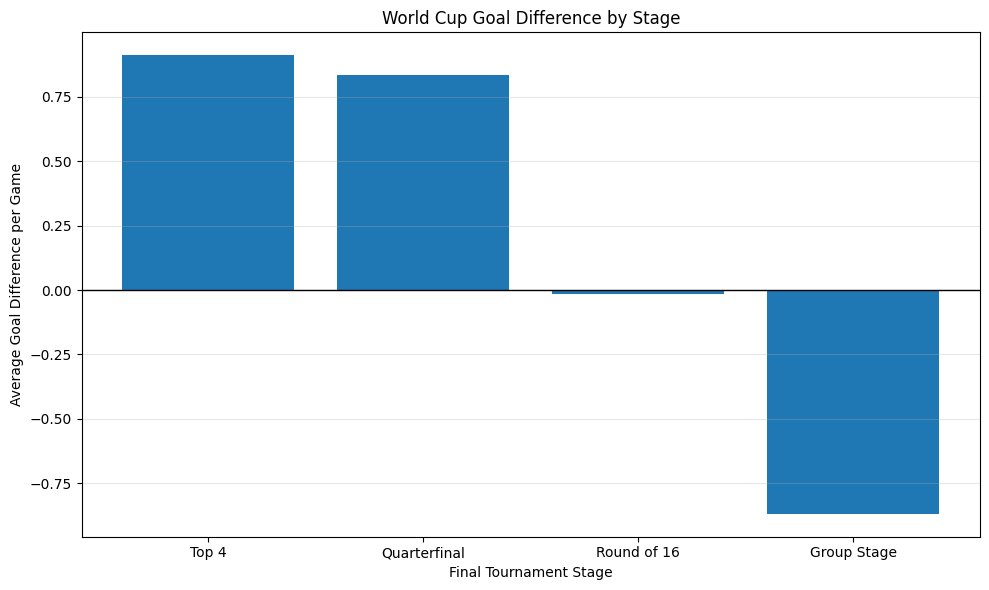

In [17]:

import matplotlib.pyplot as plt

# 기존 그룹별 통계 복사
final_summary = stage_summary.copy()

# 경기당 득실 차이 계산
final_summary["Goal Difference"] = (
    final_summary["Avg_Goals"] -
    final_summary["Avg_Conceded"]
)

# 성적 순서 지정
order = [
    "Top 4",
    "Quarterfinal",
    "Round of 16",
    "Group Stage"
]

final_summary = final_summary.loc[order]

print("월드컵 성적 그룹별 득실 차이")
display(final_summary.round(2))

# 그래프
plt.figure(figsize=(10, 6))

plt.bar(
    final_summary.index,
    final_summary["Goal Difference"]
)

plt.axhline(0, color="black", linewidth=1)

plt.title("World Cup Goal Difference by Stage")
plt.xlabel("Final Tournament Stage")
plt.ylabel("Average Goal Difference per Game")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:
%pip install -q -U openai

In [19]:
from google.colab import userdata
from openai import OpenAI

api_key = userdata.get("OPENAI_API_KEY")

client = OpenAI(api_key=api_key)

print("OpenAI API 클라이언트 준비 완료!")

OpenAI API 클라이언트 준비 완료!


In [20]:

# 2002~2022년 대한민국 기록만 선택
korea_recent = korea_history[
    korea_history["Year"].between(2002, 2022)
]

# 기사 작성에 사용할 근거 자료
fact_sheet = f"""
주제: 대한민국은 왜 월드컵에서 우승하지 못할까?
데이터: Kaggle FIFA World Cup Dataset
분석 기간: 2002~2022년

[대한민국 대회별 성적]
{korea_recent.to_string(index=False)}

[국가별 비교]
{summary.round(3).to_string()}

[최종 성적별 비교]
{stage_summary.round(3).to_string()}

[상관관계]
{correlation.round(3).to_string()}

분석 한계:
- 개별 경기 기록이 아닌 국가별 대회 집계 자료
- 상대팀 수준과 전술은 반영되지 않음
- 상관관계는 인과관계를 증명하지 않음
- FIFA 공식 자료와 독립 대조는 아직 완료되지 않음
"""

print("Fact Sheet 생성 완료!")
print(fact_sheet)


Fact Sheet 생성 완료!

주제: 대한민국은 왜 월드컵에서 우승하지 못할까?
데이터: Kaggle FIFA World Cup Dataset
분석 기간: 2002~2022년

[대한민국 대회별 성적]
 Position        Team  Games Played  Win  Draw  Loss  Goals For  Goals Against Goal Difference  Points  Year  Goals Per Game  Conceded Per Game  Win Rate
        4 South Korea             7    3     2     2          8              6               2      11  2002        1.142857           0.857143 42.857143
       17 South Korea             3    1     1     1          3              4              −1       4  2006        1.000000           1.333333 33.333333
       15 South Korea             4    1     1     2          6              8              −2       4  2010        1.500000           2.000000 25.000000
       27 South Korea             3    0     1     2          3              6              −3       1  2014        1.000000           2.000000  0.000000
       25 South Korea             3    1     0     2          3              3               0       3  2018       

In [21]:

from IPython.display import Markdown, display

prompt = f"""
너는 데이터 저널리즘 전문 기자다.

다음 Fact Sheet를 근거로
한국어 뉴스 기사를 작성하라.

기사 제목:
대한민국은 왜 월드컵에서 우승하지 못할까?

작성 조건:
1. 제목과 부제목 포함
2. 핵심 통계로 기사를 시작
3. 대한민국과 우승 경험국의 기록 비교
4. 2002년 대한민국 4강 성적 분석
5. 공격력과 수비력의 통계적 차이 설명
6. 상관관계와 인과관계를 명확하게 구분
7. 확인되지 않은 사실이나 숫자 생성 금지
8. 분석의 한계를 마지막에 명시
9. 한국어 뉴스 기사체
10. 약 1,200~1,500자
11. Markdown 형식으로 작성

[FACT SHEET]
{fact_sheet}
"""

response = client.responses.create(
    model="gpt-6-luna",
    instructions=(
        "당신은 데이터 저널리즘 전문 기자입니다. "
        "제공된 근거에 충실하고 통계를 정확히 해석하세요."
    ),
    input=prompt,
    max_output_tokens=2500
)

article = response.output_text

if not article:
    raise ValueError("기사 텍스트가 생성되지 않았습니다.")

display(Markdown(article))


# 대한민국은 왜 월드컵에서 우승하지 못할까?

## 2002년 4강은 빛났지만, 대회 전체로는 득점이 적고 실점이 많았다…기록은 우승의 ‘원인’이 아니라 성적과 함께 움직인 지표다

2002~2022년 월드컵에서 한국은 24경기 중 7승을 거두고 28골을 넣는 동안 35골을 내줬다. 경기당 득점은 1.17골, 실점은 1.46골이다. 같은 기간 아르헨티나·브라질·독일은 경기당 1.68~2.06골을 넣고 0.79~1.03골을 내줬다. 우승 경험국 세 팀과 비교하면 한국은 득점이 적고 실점이 많았지만, 이 차이만으로 우승하지 못한 이유를 단정할 수는 없다.

세 나라의 승률은 브라질과 독일이 각각 67.6%, 아르헨티나가 64.5%였다. 한국은 29.2%다. 브라질은 34경기 23승, 독일도 34경기 23승을 기록했고, 아르헨티나는 31경기에서 20승을 거뒀다. 이 집계에서 한국은 승수뿐 아니라 경기당 득점에서도 뒤지고, 실점은 더 많았다. 다만 국가별 경기 수가 다르므로 총득점·총승수보다 경기당 기록과 승률을 함께 보는 것이 적절하다.

한국의 가장 높은 성적은 2002년 4위다. 7경기에서 3승 2무 2패, 8득점 6실점을 기록했다. 경기당 1.14골을 넣고 0.86골을 내준 셈이다. 분석 기간 한국 전체의 경기당 실점 1.46골보다 낮고, 득실차도 +2였다. 2002년은 한국이 공격과 수비 양쪽에서 대회 전체 평균보다 나은 기록을 남긴 사례다. 그러나 한 차례의 4강 진출이 이후 대회 성적이나 우승 가능성을 설명해주지는 않는다.

대회 최종 성적별 집계에서도 차이가 보인다. 조별리그 탈락 팀은 경기당 평균 0.826골을 넣고 1.694골을 내준 반면, 4강 진출 팀은 1.738골을 넣고 0.827골을 실점했다. 더 많이 득점하고 덜 실점한 팀이 높은 단계에 도달한 경향이다. 한국은 분석 기간 전체로 보면 경기당 득점 1.167골, 실점 1.458골로, 4강 팀 평균과는 차이가 있다.

상관관계 분석에서도 순위 숫자가 낮을수록 좋은 성적이라는 점을 전제로, 순위와 경기당 득점은 음의 상관관계(-0.678), 순위와 실점은 양의 상관관계(0.637)를 보였다. 즉 득점이 많을수록, 실점이 적을수록 더 좋은 순위와 함께 나타나는 경향이 있었다. 이는 상관관계이지 인과관계의 증명은 아니다. 득점이나 수비 기록만으로 우승 여부를 설명할 수는 없다.

분석에는 한계가 있다. 자료는 개별 경기 기록이 아닌 국가별 대회 집계여서 상대팀 수준과 전술을 반영하지 않는다. 상관관계는 원인을 증명하지 않으며, FIFA 공식 자료와의 독립 대조도 완료되지 않았다. 따라서 이 수치들은 한국의 우승 실패를 단일 원인으로 설명하기보다, 성적과 함께 나타난 기록의 차이를 보여준다.

In [22]:

factcheck_prompt = f"""
너는 데이터 저널리즘 팩트체커다.

아래 AI 기사를 Fact Sheet와 비교해 검토하라.

[검증 기준]
1. 모든 숫자가 Fact Sheet와 일치하는가?
2. 데이터에 없는 사실을 주장했는가?
3. 상관관계를 인과관계로 잘못 설명했는가?
4. 비교 기간과 대상이 정확한가?
5. 근거 없이 우승 실패의 원인을 단정했는가?
6. 계산이나 해석 오류가 있는가?

[출력 형식]
## 팩트체크 결과

각 문제에 대해:
- 기사 원문
- 판정: PASS / ERROR / UNVERIFIED
- 이유
- 수정 제안

## 최종 판정
PASS / REVISE / HOLD

[FACT SHEET]
{fact_sheet}

[AI ARTICLE]
{article}
"""

check_response = client.responses.create(
    model="gpt-6-luna",
    instructions=(
        "근거 중심으로 기사를 검수하라. "
        "확인되지 않은 주장은 UNVERIFIED로 표시하고, "
        "검증되지 않은 내용을 임의로 확정하지 말라."
    ),
    input=factcheck_prompt,
    max_output_tokens=3000
)

factcheck_report = check_response.output_text

display(Markdown(factcheck_report))


## 팩트체크 결과

- 기사 원문: “2002~2022년 월드컵에서 한국은 24경기 중 7승을 거두고 28골을 넣는 동안 35골을 내줬다. 경기당 득점은 1.17골, 실점은 1.46골이다.”
  - 판정: **PASS**
  - 이유: Fact Sheet의 국가별 비교 수치와 일치한다. 경기당 득점 28÷24는 약 1.167골, 실점 35÷24는 약 1.458골로 반올림도 적절하다.
  - 수정 제안: 없음.

- 기사 원문: “같은 기간 아르헨티나·브라질·독일은 경기당 1.68~2.06골을 넣고 0.79~1.03골을 내줬다.”
  - 판정: **PASS**
  - 이유: Fact Sheet의 세 나라 경기당 득점은 1.677~2.059골, 실점은 0.794~1.032골이다. 기사에 제시한 범위는 반올림과 일치한다.
  - 수정 제안: 없음.

- 기사 원문: “세 나라의 승률은 브라질과 독일이 각각 67.6%, 아르헨티나가 64.5%였다. 한국은 29.2%다.”
  - 판정: **PASS**
  - 이유: Fact Sheet의 승률과 일치한다. 경기 수·승수도 정확하다.
  - 수정 제안: 없음.

- 기사 원문: “한국의 가장 높은 성적은 2002년 4위다. 7경기에서 3승 2무 2패, 8득점 6실점을 기록했다. 경기당 1.14골을 넣고 0.86골을 내준 셈이다.”
  - 판정: **PASS**
  - 이유: 2002년 대회별 성적과 경기당 수치가 Fact Sheet와 일치한다.
  - 수정 제안: 없음.

- 기사 원문: “2002년은 한국이 공격과 수비 양쪽에서 대회 전체 평균보다 나은 기록을 남긴 사례다.”
  - 판정: **UNVERIFIED**
  - 이유: Fact Sheet에는 대회 전체 참가국의 평균 기록이 제시되어 있지 않다. 앞 문장의 ‘분석 기간 한국 전체 평균’과 비교하려는 뜻이라면, ‘대회 전체 평균’이라는 표현은 비교 대상을 혼동하게 할 수 있다.
  - 수정 제안: “2002년 한국은 분석 기간 한국의 경기당 평균보다 더 많이 득점하고 적게 실점했다”처럼 비교 대상을 명시한다.

- 기사 원문: “대회 최종 성적별 집계에서도 차이가 보인다. 조별리그 탈락 팀은 경기당 평균 0.826골을 넣고 1.694골을 내준 반면, 4강 진출 팀은 1.738골을 넣고 0.827골을 실점했다.”
  - 판정: **UNVERIFIED**
  - 이유: 제시된 수치는 Fact Sheet의 `Avg_Goals`, `Avg_Conceded` 값과 일치한다. 다만 Fact Sheet에는 이 평균값이 ‘경기당’ 수치라고 명시되어 있지 않아, 기사처럼 경기당 평균으로 해석한 근거는 자료만으로 확인하기 어렵다.
  - 수정 제안: 원자료에서 평균의 산출 단위를 확인하거나, 확인 전에는 ‘평균 득점·실점’으로 표현한다.

- 기사 원문: “우승 경험국 세 팀과 비교하면…”
  - 판정: **UNVERIFIED**
  - 이유: 아르헨티나·브라질·독일의 월드컵 우승 이력은 Fact Sheet에 포함되어 있지 않다. 해당 사실이 틀렸다는 뜻은 아니지만, 이 자료만으로는 검증할 수 없다.
  - 수정 제안: 우승 이력을 별도 공식 자료로 확인·인용하거나, “비교 대상 세 나라와 비교하면”으로 바꾼다.

- 기사 원문: “상관관계 분석에서도 … 순위와 경기당 득점은 음의 상관관계(-0.678), 순위와 실점은 양의 상관관계(0.637)를 보였다.”
  - 판정: **PASS**
  - 이유: 상관계수와 방향이 Fact Sheet와 일치한다. 순위 숫자가 낮을수록 좋은 성적이라는 해석도 적절하며, 이어서 인과관계가 아님을 명시했다.
  - 수정 제안: 없음.

- 기사 원문: “자료는 개별 경기 기록이 아닌 국가별 대회 집계여서 상대팀 수준과 전술을 반영하지 않는다. 상관관계는 원인을 증명하지 않으며, FIFA 공식 자료와의 독립 대조도 완료되지 않았다.”
  - 판정: **PASS**
  - 이유: Fact Sheet의 분석 한계를 정확히 반영했다.
  - 수정 제안: 없음.

## 최종 판정

**REVISE**

핵심 수치와 상관관계 해석은 대체로 정확하고, 우승 실패의 원인을 단정하지도 않았다. 다만 ‘대회 전체 평균’의 비교 대상과 최종 성적별 평균의 단위는 분명히 해야 한다. ‘우승 경험국’ 표현도 별도 근거를 추가하거나 표현을 완화하는 것이 좋다.

In [23]:

from IPython.display import Markdown, display

revision_prompt = f"""
너는 데이터 저널리즘 신문의 편집장이다.

다음 기사와 팩트체크 보고서를 참고해
최종 기사 수정본을 작성하라.

[수정 원칙]
1. PASS 항목의 정확한 수치는 유지한다.
2. UNVERIFIED 항목은 근거가 없으면 삭제한다.
3. 2002년 대회 전체 평균과의 비교는 삭제한다.
4. 성적 그룹별 평균의 계산 단위를 정확히 설명한다.
5. 우승 경험국의 우승 이력은 추가 검증 전까지
   "비교 대상 국가" 등 중립적인 표현으로 바꾼다.
6. 상관관계를 인과관계로 설명하지 않는다.
7. 근거 없는 새로운 사실을 추가하지 않는다.
8. 기사 제목·부제·소제목·본문을 구분한다.
9. 한국어 뉴스 기사체로 작성한다.
10. 마지막에 데이터 출처와 분석 한계를 표시한다.

[FACT SHEET]
{fact_sheet}

[원본 기사]
{article}

[팩트체크 결과]
{factcheck_report}

수정된 기사 본문만 Markdown 형식으로 출력하라.
"""

revised_response = client.responses.create(
    model="gpt-6-luna",
    instructions=(
        "당신은 정확성과 근거를 최우선으로 하는 "
        "데이터 저널리즘 편집장입니다."
    ),
    input=revision_prompt,
    max_output_tokens=3500
)

revised_article = revised_response.output_text

if not revised_article:
    raise ValueError("수정 기사가 생성되지 않았습니다.")

display(Markdown(revised_article))


# 대한민국은 왜 월드컵에서 우승하지 못했을까

## 2002~2022년 24경기에서 7승…비교 대상 국가보다 경기당 득점은 적고 실점은 많았다

한국의 기록은 성적과 함께 움직인 지표를 보여줄 뿐, 우승하지 못한 원인을 단독으로 설명하지는 않는다.

### 비교 대상 국가보다 낮은 승률

2002~2022년 월드컵에서 한국은 24경기 중 7승을 거뒀다. 28골을 넣고 35골을 내줬으며, 경기당 득점은 1.17골, 실점은 1.46골이다.

비교 대상인 아르헨티나·브라질·독일은 경기당 1.68~2.06골을 넣고 0.79~1.03골을 내줬다. 승률은 브라질과 독일이 각각 67.6%, 아르헨티나가 64.5%였고, 한국은 29.2%였다. 브라질과 독일은 각각 34경기에서 23승, 아르헨티나는 31경기에서 20승을 기록했다.

국가별 경기 수가 다르므로 총득점이나 총승수만 비교하기보다 경기당 기록과 승률을 함께 볼 필요가 있다. 이 수치에서는 한국이 비교 대상 국가들보다 경기당 득점은 적고 실점은 많았다. 다만 이런 차이만으로 우승하지 못한 이유를 단정할 수는 없다.

### 2002년은 한국의 최고 성적

한국의 분석 기간 중 최고 성적은 2002년 4위다. 당시 7경기에서 3승 2무 2패를 기록했고, 8득점 6실점을 했다. 경기당 득점은 1.14골, 실점은 0.86골이었다.

2002년 한국의 경기당 득점은 분석 기간 전체 평균인 1.17골보다 낮았고, 실점은 전체 평균인 1.46골보다 낮았다. 한 차례의 4강 진출 기록만으로 이후 대회의 성적이나 우승 가능성을 설명할 수는 없다.

### 성적 단계별 평균과 상관관계

최종 성적 단계별 자료에는 조별리그 탈락 팀 96개, 16강 진출 팀 48개, 8강 진출 팀 24개, 4강 진출 팀 24개가 제시돼 있다. 자료에 기재된 각 단계의 평균 득점·실점은 조별리그 탈락 팀 0.826골·1.694골, 4강 진출 팀 1.738골·0.827골이다.

이 값은 성적 단계별 팀을 대상으로 제시된 평균이다. 다만 자료에는 평균이 경기당 수치인지, 대회 전체 팀별 누적 기록의 평균인지 산출 단위가 명시돼 있지 않다. 따라서 이를 경기당 평균으로 해석하지 않는다.

상관관계 분석에서 순위 숫자가 낮을수록 좋은 성적이라는 점을 전제로, 순위와 경기당 득점은 음의 상관관계(-0.678), 순위와 경기당 실점은 양의 상관관계(0.637)를 보였다. 즉 득점이 많거나 실점이 적은 경우 더 좋은 순위와 함께 나타나는 경향이 있었다. 이는 상관관계이며 인과관계를 증명하지 않는다.

### 데이터 출처와 분석 한계

출처는 Kaggle의 FIFA World Cup Dataset이며, 분석 기간은 2002~2022년이다. 자료는 개별 경기 기록이 아닌 국가별 대회 집계 자료로, 상대팀 수준과 전술은 반영하지 않는다. 성적 단계별 평균의 산출 단위는 자료에 명시돼 있지 않으며, FIFA 공식 자료와의 독립 대조도 완료되지 않았다. 상관관계는 원인을 증명하지 않는다.

In [24]:

final_prompt = f"""
너는 데이터 저널리즘 전문 교열 기자다.

다음 기사를 최종 교정하라.

[반드시 수정할 사항]

1. 숫자가 붙어 출력된 부분을 수정한다.

국가별 경기당 득점:
- 아르헨티나: 1.68골
- 브라질: 1.88골
- 독일: 2.06골
- 대한민국: 1.17골

국가별 경기당 실점:
- 아르헨티나: 1.03골
- 브라질: 0.88골
- 독일: 0.79골
- 대한민국: 1.46골

2. 2002년 한국의 경기당 실점 0.86골을
2002~2022년 한국 전체 평균 1.46골과
비교한 것임을 명확히 한다.

3. 성적 그룹별 평균은 각 참가팀의
경기당 득점·실점을 계산한 뒤,
그 값을 그룹별로 평균 낸 결과라고 설명한다.

4. 승부차기 결과를 별도 승리로 계산하지 않은
데이터셋 기준임을 표시한다.

5. 분석 결과만으로 우승 실패의
원인을 단정하지 않는다.

6. 새로운 통계나 사실을 추가하지 않는다.

7. 제목, 부제, 소제목, 본문, 출처를
Markdown 형식으로 정리한다.

8. 최종 기사 본문만 출력한다.

[FACT SHEET]
{fact_sheet}

[교정 대상 기사]
{revised_article}
"""

final_response = client.responses.create(
    model="gpt-6-luna",
    instructions=(
        "원본 데이터와 수치 일치를 최우선으로 하는 "
        "한국어 뉴스 교열 기자다."
    ),
    input=final_prompt,
    max_output_tokens=3500
)

final_article = final_response.output_text

if not final_article:
    raise ValueError("교정 기사가 생성되지 않았습니다.")

from IPython.display import Markdown, display
display(Markdown(final_article))


# 한국은 왜 월드컵에서 우승하지 못했을까…기록만으로 원인을 단정할 수는 없다

## 2002~2022년 24경기에서 7승…비교 대상 국가보다 경기당 득점은 적고 실점은 많았다

한국의 기록은 성적과 함께 나타난 지표를 보여줄 뿐, 우승하지 못한 원인을 단독으로 설명하지는 않는다.

### 비교 대상 국가보다 낮은 승률

2002~2022년 월드컵에서 한국은 24경기 중 7승을 거뒀다. 28골을 넣고 35골을 내줬으며, 경기당 득점은 1.17골, 실점은 1.46골이다.

비교 대상 국가의 경기당 득점은 아르헨티나 1.68골, 브라질 1.88골, 독일 2.06골이다. 경기당 실점은 아르헨티나 1.03골, 브라질 0.88골, 독일 0.79골이었다. 승률은 브라질과 독일이 각각 67.6%, 아르헨티나가 64.5%였고, 한국은 29.2%였다. 브라질과 독일은 각각 34경기에서 23승, 아르헨티나는 31경기에서 20승을 기록했다.

국가별 경기 수가 다르므로 총득점이나 총승수만 비교하기보다 경기당 기록과 승률을 함께 볼 필요가 있다. 이 수치에서는 한국이 비교 대상 국가들보다 경기당 득점은 적고 실점은 많았다. 다만 이 차이만으로 우승하지 못한 원인을 단정할 수는 없다. 승수는 승부차기 결과를 별도 승리로 계산하지 않은 데이터셋 기준이다.

### 2002년은 한국의 최고 성적

한국의 분석 기간 중 최고 성적은 2002년 4위다. 당시 7경기에서 3승 2무 2패를 기록했고, 8득점 6실점을 했다. 경기당 득점은 1.14골, 실점은 0.86골이었다.

2002년 한국의 경기당 득점은 2002~2022년 한국 전체 평균인 1.17골보다 낮았다. 경기당 실점 0.86골도 같은 기간 한국 전체 평균인 1.46골과 비교하면 낮은 수치다. 한 차례의 4강 진출 기록만으로 이후 대회의 성적이나 우승 가능성을 설명할 수는 없다.

### 성적 단계별 평균과 상관관계

최종 성적 단계별 자료에는 조별리그 탈락 팀 96개, 16강 진출 팀 48개, 8강 진출 팀 24개, 4강 진출 팀 24개가 제시돼 있다. 각 참가팀의 경기당 득점과 경기당 실점을 먼저 계산한 뒤, 그 값을 성적 단계별로 평균 낸 결과다. 조별리그 탈락 팀의 평균은 경기당 0.826득점·1.694실점, 8강 진출 팀은 1.642득점·0.808실점, 16강 진출 팀은 1.240득점·1.255실점, 4강 진출 팀은 1.738득점·0.827실점이다.

상관관계 분석에서 순위 숫자가 낮을수록 좋은 성적이라는 점을 전제로, 순위와 경기당 득점은 음의 상관관계(-0.678), 순위와 경기당 실점은 양의 상관관계(0.637)를 보였다. 득점이 많거나 실점이 적은 경우 더 좋은 순위와 함께 나타나는 경향이 있었지만, 상관관계가 인과관계를 증명하는 것은 아니다.

### 데이터 출처와 분석 한계

**출처:** Kaggle FIFA World Cup Dataset  
**분석 기간:** 2002~2022년

자료는 개별 경기 기록이 아닌 국가별 대회 집계 자료로, 상대팀 수준과 전술은 반영하지 않는다. FIFA 공식 자료와의 독립 대조는 아직 완료되지 않았다. 상관관계는 원인을 증명하지 않는다.

In [25]:

from google.colab import files
from datetime import date

filename = "WHY_NOT_KOREA_Final_Article.md"

with open(filename, "w", encoding="utf-8") as f:
    f.write(final_article)

print("최종 기사 저장 완료:", filename)

files.download(filename)


최종 기사 저장 완료: WHY_NOT_KOREA_Final_Article.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

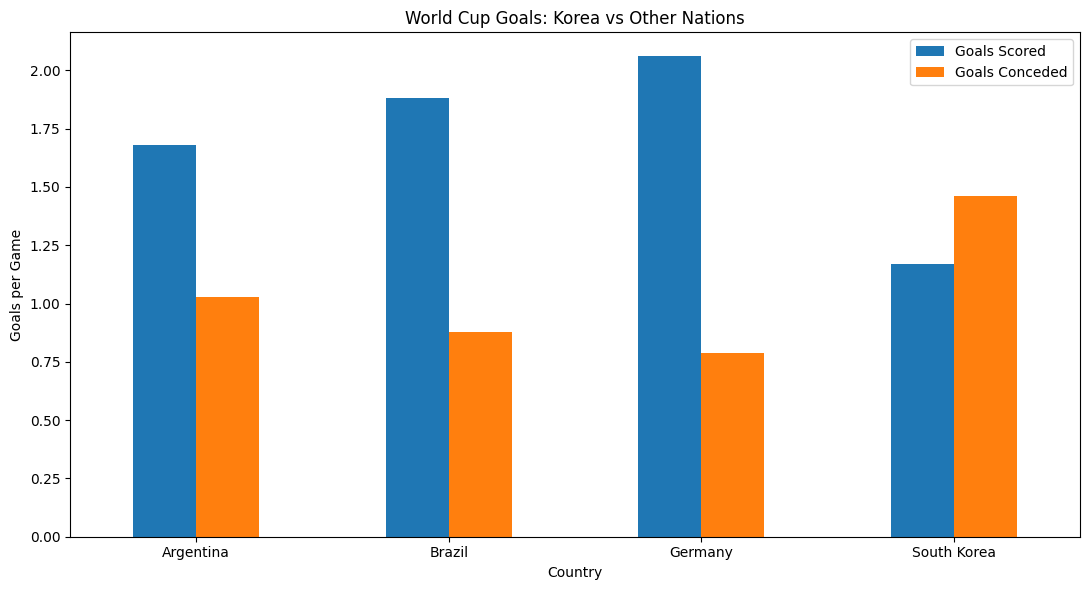

In [26]:

import matplotlib.pyplot as plt

chart_data = summary[
    ["Goals Per Game", "Conceded Per Game"]
].round(2)

ax = chart_data.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("World Cup Goals: Korea vs Other Nations")
plt.ylabel("Goals per Game")
plt.xlabel("Country")
plt.xticks(rotation=0)
plt.legend(["Goals Scored", "Goals Conceded"])
plt.tight_layout()

plt.savefig(
    "WHY_NOT_KOREA_Comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# 한국은 왜 월드컵에서 우승하지 못했을까…기록만으로 원인을 단정할 수는 없다

## 2002~2022년 24경기에서 7승…비교 대상 국가보다 경기당 득점은 적고 실점은 많았다

한국의 기록은 성적과 함께 나타난 지표를 보여줄 뿐, 우승하지 못한 원인을 단독으로 설명하지는 않는다.

### 비교 대상 국가보다 낮은 승률

2002~2022년 월드컵에서 한국은 24경기 중 7승을 거뒀다. 28골을 넣고 35골을 내줬으며, 경기당 득점은 1.17골, 실점은 1.46골이다.

비교 대상 국가의 경기당 득점은 아르헨티나 1.68골, 브라질 1.88골, 독일 2.06골이다. 경기당 실점은 아르헨티나 1.03골, 브라질 0.88골, 독일 0.79골이었다. 승률은 브라질과 독일이 각각 67.6%, 아르헨티나가 64.5%였고, 한국은 29.2%였다. 브라질과 독일은 각각 34경기에서 23승, 아르헨티나는 31경기에서 20승을 기록했다.

국가별 경기 수가 다르므로 총득점이나 총승수만 비교하기보다 경기당 기록과 승률을 함께 볼 필요가 있다. 이 수치에서는 한국이 비교 대상 국가들보다 경기당 득점은 적고 실점은 많았다. 다만 이 차이만으로 우승하지 못한 원인을 단정할 수는 없다. 승수는 승부차기 결과를 별도 승리로 계산하지 않은 데이터셋 기준이다.

### 2002년은 한국의 최고 성적

한국의 분석 기간 중 최고 성적은 2002년 4위다. 당시 7경기에서 3승 2무 2패를 기록했고, 8득점 6실점을 했다. 경기당 득점은 1.14골, 실점은 0.86골이었다.

2002년 한국의 경기당 득점은 2002~2022년 한국 전체 평균인 1.17골보다 낮았다. 경기당 실점 0.86골도 같은 기간 한국 전체 평균인 1.46골과 비교하면 낮은 수치다. 한 차례의 4강 진출 기록만으로 이후 대회의 성적이나 우승 가능성을 설명할 수는 없다.

### 성적 단계별 평균과 상관관계

최종 성적 단계별 자료에는 조별리그 탈락 팀 96개, 16강 진출 팀 48개, 8강 진출 팀 24개, 4강 진출 팀 24개가 제시돼 있다. 각 참가팀의 경기당 득점과 경기당 실점을 먼저 계산한 뒤, 그 값을 성적 단계별로 평균 낸 결과다. 조별리그 탈락 팀의 평균은 경기당 0.826득점·1.694실점, 8강 진출 팀은 1.642득점·0.808실점, 16강 진출 팀은 1.240득점·1.255실점, 4강 진출 팀은 1.738득점·0.827실점이다.

상관관계 분석에서 순위 숫자가 낮을수록 좋은 성적이라는 점을 전제로, 순위와 경기당 득점은 음의 상관관계(-0.678), 순위와 경기당 실점은 양의 상관관계(0.637)를 보였다. 득점이 많거나 실점이 적은 경우 더 좋은 순위와 함께 나타나는 경향이 있었지만, 상관관계가 인과관계를 증명하는 것은 아니다.

### 데이터 출처와 분석 한계

**출처:** Kaggle FIFA World Cup Dataset  
**분석 기간:** 2002~2022년

자료는 개별 경기 기록이 아닌 국가별 대회 집계 자료로, 상대팀 수준과 전술은 반영하지 않는다. FIFA 공식 자료와의 독립 대조는 아직 완료되지 않았다. 상관관계는 원인을 증명하지 않는다.

## 데이터 시각화

### 대한민국과 주요 국가의 경기당 득점·실점 비교

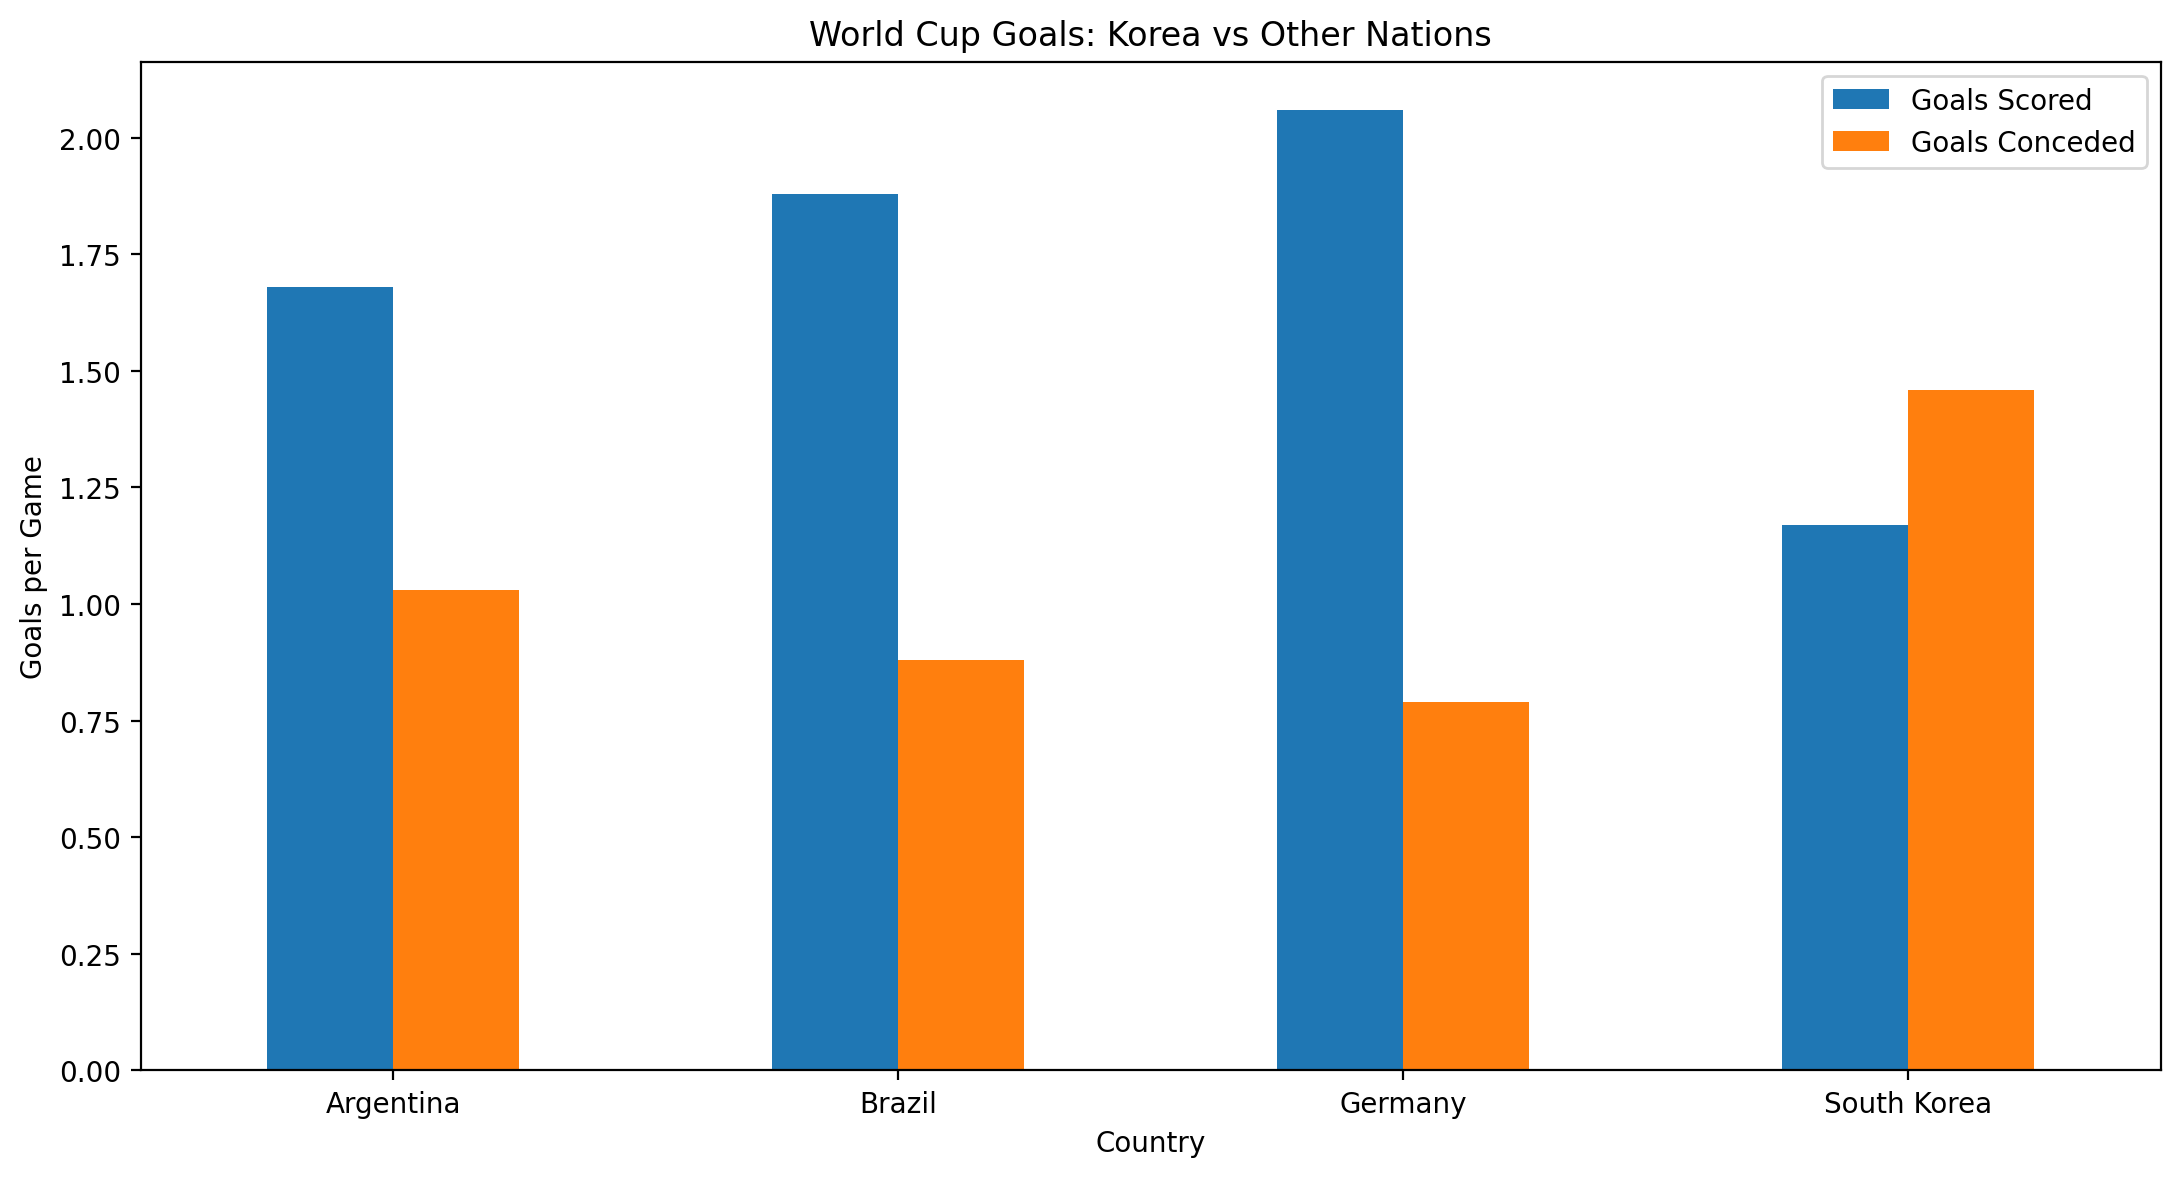

*출처: Kaggle FIFA World Cup Dataset / 분석 기간: 2002~2022년*

In [27]:

from IPython.display import display, Markdown, Image

# 최종 기사 표시
display(Markdown(final_article))

# 분석 그래프 추가
display(Markdown("## 데이터 시각화"))

display(Markdown(
    "### 대한민국과 주요 국가의 경기당 득점·실점 비교"
))

display(Image(
    filename="WHY_NOT_KOREA_Comparison.png",
    width=900
))

display(Markdown(
    "*출처: Kaggle FIFA World Cup Dataset / "
    "분석 기간: 2002~2022년*"
))


In [28]:

# 대한민국 국가별 통계 확인
kr = summary.loc["South Korea"]

checks = {
    "한국 전체 경기 수": kr["Games"] == 24,
    "한국 승리 수": kr["Wins"] == 7,
    "한국 경기당 득점": round(kr["Goals Per Game"], 2) == 1.17,
    "한국 경기당 실점": round(kr["Conceded Per Game"], 2) == 1.46,
    "한국 승률": round(kr["Win Rate (%)"], 2) == 29.17,

    "4강 평균 득점": round(
        stage_summary.loc["Top 4", "Avg_Goals"], 2
    ) == 1.74,

    "4강 평균 실점": round(
        stage_summary.loc["Top 4", "Avg_Conceded"], 2
    ) == 0.83,

    "득점 상관계수": round(
        correlation.loc["Position", "Goals Per Game"], 3
    ) == -0.678,

    "실점 상관계수": round(
        correlation.loc["Position", "Conceded Per Game"], 3
    ) == 0.637
}

print("=== 최종 데이터 검증 결과 ===")

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL"), "-", name)

print("\n검증 결과:", sum(checks.values()), "/", len(checks))


=== 최종 데이터 검증 결과 ===
PASS - 한국 전체 경기 수
PASS - 한국 승리 수
PASS - 한국 경기당 득점
PASS - 한국 경기당 실점
PASS - 한국 승률
PASS - 4강 평균 득점
PASS - 4강 평균 실점
PASS - 득점 상관계수
PASS - 실점 상관계수

검증 결과: 9 / 9
